# ARIMAX en el QQQ real: ¿dónde queda el Nasdaq si el miedo se dispara?
### Serie "El modelo que pronostica el futuro" · Castle Quant

**Activo:** QQQ diario desde 2005 + el **VIX** (índice de volatilidad implícita del S&P 500, el "índice del miedo"). **Todo es cálculo sobre datos reales** descargados con `yfinance`; no hay simulación.

**Flujo:** ecuación → datos → ¿por qué el VIX? → entrenamiento → **la trampa** (validación fuera de muestra) → **la aplicación**: proyección por escenarios del VIX.

| Figura | Bloque | Frase en la que entra |
|---|---|---|
| 1 · QQQ contra VIX | 2 | "El VIX, el índice del miedo, se mueve al revés del Nasdaq" |
| 2 · Mismo día vs. día anterior | 2 | "Por cada diez por ciento que sube el VIX, el QQQ cae…" |
| 3 · La trampa fuera de muestra | 2 | "Si lo pruebas así, acierta… Con el VIX de ayer…" |
| 4 · Validación de escenarios | 3 | "Le di al modelo el camino real del VIX…" |
| 5 · Proyección por escenarios | 3 | "Si el VIX se duplica, el QQQ…" |

**Las cifras que dices al aire se leen de los `print()` de cada celda.** Cambian con la fecha en que corras el notebook.

**Colores de marca Castle.** En la celda de setup elige `OPCION = 'imperial'` (tonos profundos sobre Oxford White) u `OPCION = 'signal'` (tonos claros sobre blanco).



ARIMAX = el ARIMA de la parte 1 **+ una variable externa** $x_t$. Con $d = 1$, sobre el retorno diario $\Delta y_t$ (log-precio del QQQ):

$$\Delta y_t \;=\; c \;+\; \underbrace{\phi_1 \Delta y_{t-1} + \dots}_{\text{memoria del precio}} \;+\; \underbrace{\beta\,\Delta x_t}_{\text{el mundo de afuera}} \;+\; \underbrace{\theta_1 \varepsilon_{t-1} + \dots}_{\text{corrección de errores}} \;+\; \varepsilon_t$$

Aquí $x_t = \log(\text{VIX}_t)$, así que $\Delta x_t$ es el cambio porcentual del VIX. $\beta$ responde: **cuando el miedo sube 1%, ¿cuánto se mueve el Nasdaq?**

| Uso | Qué X entra | ¿Es válido? |
|---|---|---|
| Pronosticar mañana | $x_t$ del mismo día | **No**: el VIX de hoy solo se conoce al cierre (sección 4) |
| Pronosticar mañana | $x_{t-1}$ del día anterior | Sí, pero hay que medir si aporta (sección 4) |
| **Proyectar escenarios** | un camino supuesto de $x$ | **Sí**: es la pregunta "si el VIX hace esto, ¿qué hace el QQQ?" (sección 5) |

In [ ]:
!pip install -q yfinance statsmodels

import os, itertools, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
warnings.simplefilter('ignore')

# =====================  ELIGE LA OPCIÓN DE COLOR  =====================
OPCION = 'imperial'   # 'imperial' = tonos profundos sobre Oxford White · 'signal' = tonos claros sobre blanco
# ======================================================================

# --- Paletas Castle Capital (Design System). Siempre fondo claro. ---
PALETAS = {
    'imperial': dict(BG='#F4F4F0', PANEL_BG='#FFFFFF', FG='#3D3D3D', TITLE='#1B3A6B',
                     GRID='#E2E2DB', SPINE='#C9C9C0', MAIN='#1B3A6B', ALERT='#C97A3A',
                     SECOND='#2B5497', GOLD='#C9A84C', GOLD_TXT='#8C7325', MUTED='#6B6B6B',
                     SOFT='#D5DCE8'),
    'signal':   dict(BG='#FFFFFF', PANEL_BG='#E8EDF5', FG='#3D3D3D', TITLE='#1B3A6B',
                     GRID='#E8EDF5', SPINE='#D5DCE8', MAIN='#4A8FD4', ALERT='#E8954F',
                     SECOND='#2B5497', GOLD='#C9A84C', GOLD_TXT='#8C7325', MUTED='#6B6B6B',
                     SOFT='#E8EDF5'),
}
P = PALETAS[OPCION]
BG, PANEL_BG, FG, TITLE, GRID = P['BG'], P['PANEL_BG'], P['FG'], P['TITLE'], P['GRID']
MAIN, ALERT, SECOND, GOLD, GOLD_TXT, MUTED, SOFT = (P[k] for k in
    ['MAIN', 'ALERT', 'SECOND', 'GOLD', 'GOLD_TXT', 'MUTED', 'SOFT'])
ORANGE_SOFT = '#F2B17A'

# --- Tipografía: fuentes del sistema (sin descargas, sin avisos) ---
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
SERIF = ['DejaVu Serif']   # titulares
SANS  = ['DejaVu Sans']    # texto
NUM   = ['DejaVu Sans']    # cifras y etiquetas

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG, 'savefig.facecolor': BG, 'figure.dpi': 110,
    'text.color': FG, 'axes.labelcolor': FG, 'axes.edgecolor': P['SPINE'],
    'xtick.color': MUTED, 'ytick.color': MUTED, 'grid.color': GRID,
    'legend.facecolor': PANEL_BG, 'legend.edgecolor': GRID, 'legend.labelcolor': FG, 'legend.frameon': False,
    'font.family': SANS, 'font.size': 13, 'mathtext.fontset': 'dejavuserif',
    'axes.titlesize': 24, 'axes.titlelocation': 'left', 'axes.titlepad': 14,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 1.0, 'grid.linestyle': '-', 'grid.linewidth': 0.7,
})

EYEBROW = 'SERIE ARIMA · ARIMAX EN EL QQQ'

def marca(ax, titulo, eyebrow=EYEBROW):
    """Eyebrow Barlow en oro ENCIMA del titular serif Imperial + cifras de ejes en Barlow."""
    ax.set_title(titulo, fontfamily=SERIF, fontweight='bold', color=TITLE, pad=10)
    ax.annotate(eyebrow, xy=(0, 1), xycoords='axes fraction', xytext=(0, 46), textcoords='offset points',
                fontfamily=NUM, fontweight='semibold', fontsize=11, color=GOLD_TXT, va='bottom', ha='left')
    ax.tick_params(labelsize=12)

def rotulo(ax, texto='Datos reales · QQQ y VIX (Yahoo Finance)'):
    ax.text(0.99, 0.015, texto, transform=ax.transAxes, ha='right', va='bottom', fontsize=10, color=MUTED)

def pct(x, dec=1):
    return f'{x:+.{dec}f}%'.replace('.', ',')

print(f'Setup listo · opción de color: {OPCION}')

Setup listo · opción de color: imperial


## 1. Datos

Se modela el **log-precio** del QQQ (igual que en la parte 1) y el **log del VIX** como variable externa.
Partición temporal sin barajar: los últimos `N_TEST` días quedan fuera y no se tocan hasta la sección 4.

In [ ]:
import yfinance as yf
TICKER = 'QQQ'
START  = '2005-01-01'
END    = pd.Timestamp.today().strftime('%Y-%m-%d')
N_TEST = 250                                    # ~1 año bursátil fuera de muestra

raw = yf.download([TICKER, '^VIX'], start=START, end=END, auto_adjust=True, progress=False)['Close']
df = raw.rename(columns={TICKER: 'qqq', '^VIX': 'vix'})[['qqq', 'vix']].dropna()
if df.empty:
    raise RuntimeError('No llegaron datos: revisa la conexión o el TICKER.')

fechas = df.index
y  = pd.Series(np.log(df['qqq'].values), name='log_qqq')   # índice entero: sin avisos de frecuencia
lv = pd.Series(np.log(df['vix'].values), name='log_vix')
y_train, y_test = y.iloc[:-N_TEST], y.iloc[-N_TEST:]
print(f'{TICKER}: {len(y):,} sesiones ({fechas[0]:%d-%m-%Y} → {fechas[-1]:%d-%m-%Y})')
print(f'Entrenamiento: {len(y_train):,} | Prueba: {len(y_test):,} (desde {fechas[-N_TEST]:%d-%m-%Y})')
print(f'Último cierre: QQQ ${df["qqq"].iloc[-1]:,.2f} · VIX {df["vix"].iloc[-1]:.2f}')

QQQ: 5,496 sesiones (03-01-2005 → 05-11-2026)
Entrenamiento: 5,246 | Prueba: 250 (desde 07-11-2025)
Último cierre: QQQ $647.05 · VIX 28.18


## 2. Bloque 2 — ¿Por qué el VIX?

### Figura 1 · El Nasdaq contra el índice del miedo
QQQ (azul, eje izquierdo) y VIX (naranja, eje derecho **invertido**: arriba = calma, abajo = pánico). Cuando el miedo sube, el Nasdaq cae: las dos curvas se mueven casi como espejo.
Lee del `print()` la correlación de los retornos diarios. Cambia `ANIOS` para ver más o menos historia.

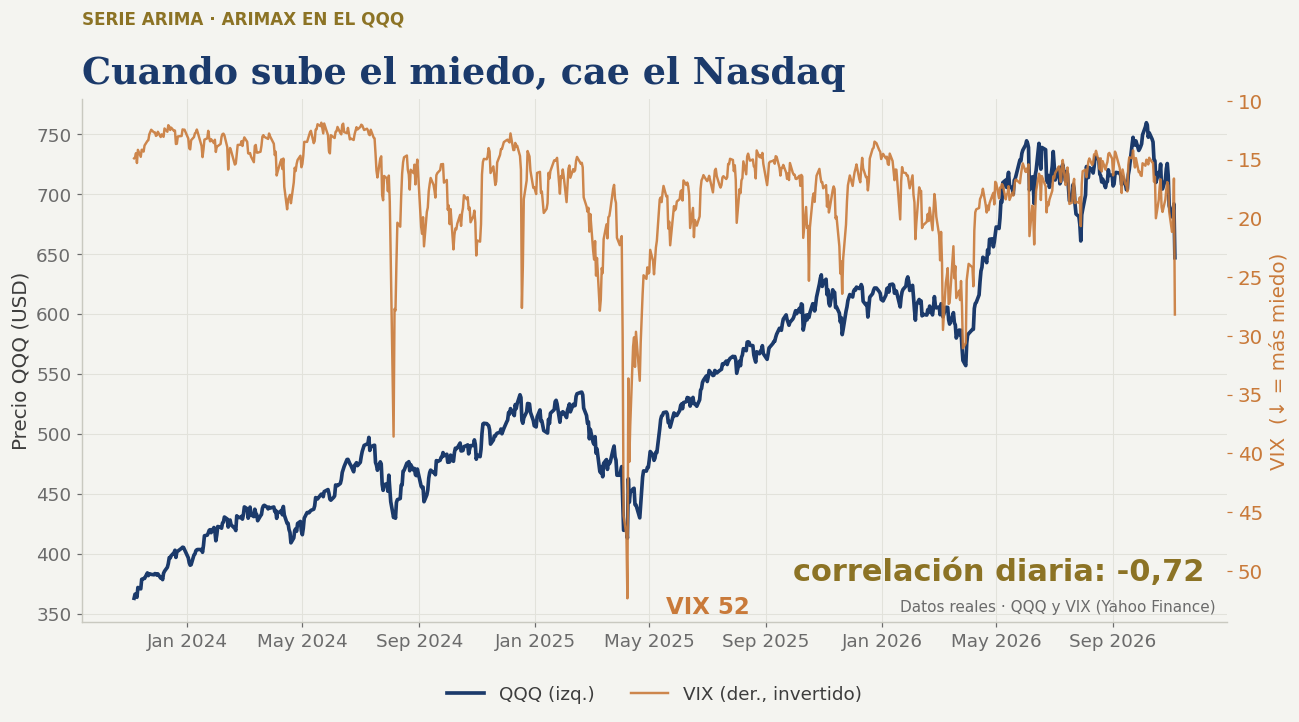

Correlación retorno QQQ vs. cambio del VIX, MISMO día: -0.72
Correlación retorno QQQ vs. cambio del VIX del DÍA ANTERIOR: 0.05


In [ ]:
ANIOS = 3
r  = y.diff()                     # retorno diario del QQQ (log)
dv = lv.diff()                    # cambio diario del VIX (log)
corr_hoy, corr_ayer = r.corr(dv), r.corr(dv.shift(1))

ini = fechas[-1] - pd.DateOffset(years=ANIOS)
m = fechas >= ini
fig, ax = plt.subplots(figsize=(12, 6.8))
ax.plot(fechas[m], df['qqq'].values[m], color=MAIN, lw=2.4, label='QQQ (izq.)')
ax.set_ylabel('Precio QQQ (USD)')
ax2 = ax.twinx()
ax2.plot(fechas[m], df['vix'].values[m], color=ALERT, lw=1.6, alpha=0.9, label='VIX (der., invertido)')
ax2.invert_yaxis(); ax2.grid(False)
ax2.set_ylabel('VIX  (↓ = más miedo)', color=ALERT)
ax2.tick_params(colors=ALERT)
for s in ['top']: ax2.spines[s].set_visible(False)
i_max = np.argmax(df['vix'].values[m])
ax2.annotate(f'VIX {df["vix"].values[m][i_max]:.0f}', xy=(fechas[m][i_max], df['vix'].values[m][i_max]),
             xytext=(25, -10), textcoords='offset points', fontsize=15, fontfamily=NUM,
             fontweight='semibold', color=ALERT)
ax.text(0.98, 0.08, f'correlación diaria: {corr_hoy:.2f}'.replace('.', ','), transform=ax.transAxes, ha='right',
        fontsize=20, fontfamily=NUM, fontweight='semibold', color=GOLD_TXT)
marca(ax, 'Cuando sube el miedo, cae el Nasdaq')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=2, fontsize=12)
rotulo(ax)
plt.tight_layout(); plt.show()

print(f'Correlación retorno QQQ vs. cambio del VIX, MISMO día: {corr_hoy:.2f}')
print(f'Correlación retorno QQQ vs. cambio del VIX del DÍA ANTERIOR: {corr_ayer:.2f}')

## 3. Entrenamiento del ARIMAX

Se busca el orden (p, q) por **BIC** solo con el entrenamiento, igual que en la parte 1, ahora con el VIX como X. Luego se estima β por máxima verosimilitud.


In [9]:
def ajustar(serie, exog, orden):
    return ARIMA(serie, exog=exog, order=orden, trend='t').fit()

grid = []
for p_, q_ in itertools.product(range(3), range(3)):
    try:
        m_ = ajustar(y_train, lv.iloc[:-N_TEST], (p_, 1, q_))
        grid.append((m_.bic, p_, q_))
    except Exception:
        pass
_, p, q = min(grid)
ORDEN = (p, 1, q)

arimax = ajustar(y_train, lv.iloc[:-N_TEST], ORDEN)
beta, beta_p = arimax.params['log_vix'], arimax.pvalues['log_vix']
efecto10 = (np.exp(beta * np.log(1.10)) - 1) * 100
efecto65 = (np.exp(beta * np.log(1.65)) - 1) * 100
tabla = pd.DataFrame({'Coeficiente': arimax.params, 'p-valor': arimax.pvalues}).round(5)
tabla.index = [i.replace('log_vix', 'β (VIX)').replace('ar.L', 'φ').replace('ma.L', 'θ')
               .replace('drift', 'deriva c').replace('sigma2', 'σ²') for i in tabla.index]
print(f'Orden elegido por BIC: ARIMAX{ORDEN}')
print(f'β del VIX = {beta:.4f}  (p-valor {beta_p:.1e})')
print(f'→ Si el VIX sube 10%, el QQQ se mueve {efecto10:+.2f}% ese mismo día')
print(f'→ Si el VIX sube 65%, el QQQ se mueve {efecto65:+.2f}% ese mismo día')
print(f'→ Si el VIX se duplica, el QQQ se mueve {(2**beta - 1)*100:+.1f}%')
tabla

Orden elegido por BIC: ARIMAX(1, 1, 0)
β del VIX = -0.1288  (p-valor 0.0e+00)
→ Si el VIX sube 10%, el QQQ se mueve -1.22% ese mismo día
→ Si el VIX sube 65%, el QQQ se mueve -6.25% ese mismo día
→ Si el VIX se duplica, el QQQ se mueve -8.5%


,Coeficiente,p-valor
deriva c,0.00056,0.00001
β (VIX),-0.12879,0.00000
φ1,-0.07687,0.00000
σ²,0.00009,0.00000


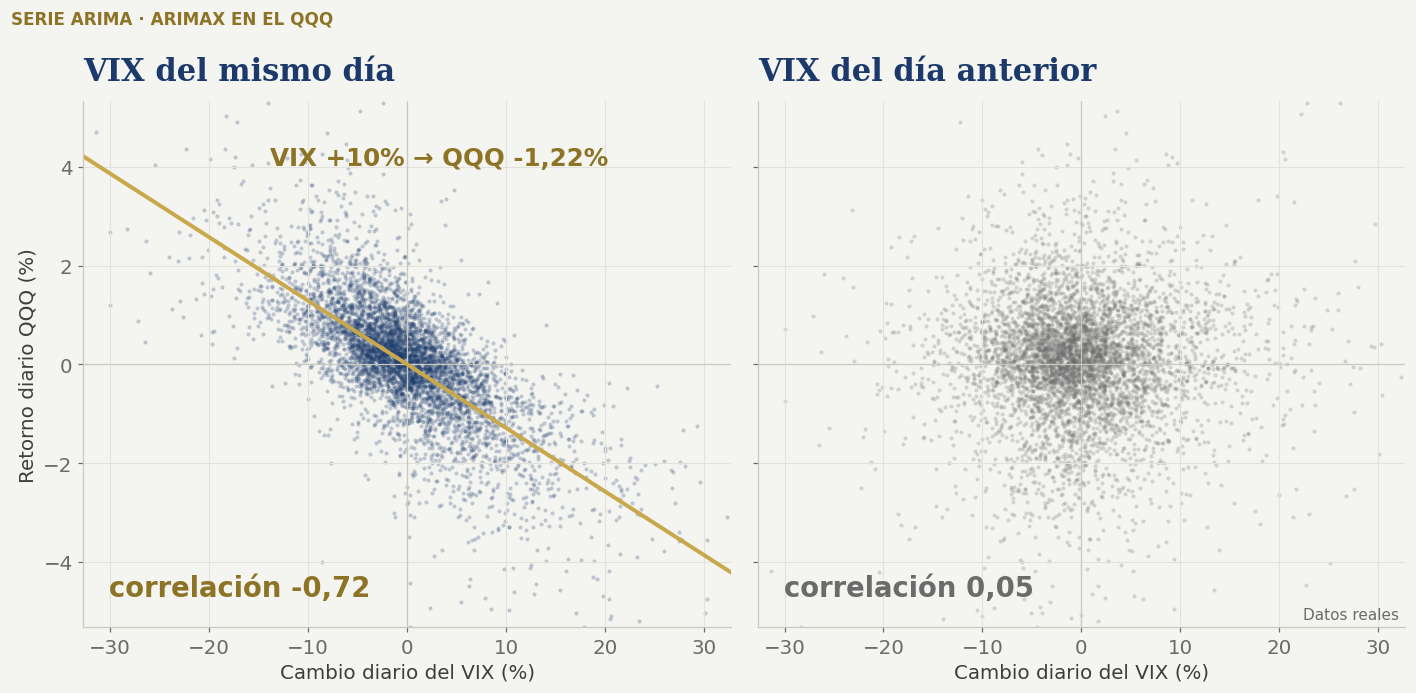

Pendiente β: VIX +10% → QQQ -1.22%
Correlación mismo día: -0.72 · día anterior: 0.05


In [ ]:
xx, yy = dv.values[1:] * 100, r.values[1:] * 100
xl, yl = dv.shift(1).values[2:] * 100, r.values[2:] * 100
lim_x, lim_y = np.nanpercentile(np.abs(xx), 99.5), np.nanpercentile(np.abs(yy), 99.5)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.4), sharey=True)
for ax, a, b, col, tit, cc in [(axes[0], xx, yy, MAIN, 'VIX del mismo día', corr_hoy),
                               (axes[1], xl, yl, MUTED, 'VIX del día anterior', corr_ayer)]:
    ax.scatter(a, b, s=7, color=col, alpha=0.25, lw=0)
    ax.axhline(0, color=P['SPINE'], lw=0.8); ax.axvline(0, color=P['SPINE'], lw=0.8)
    ax.set_xlim(-lim_x, lim_x); ax.set_ylim(-lim_y, lim_y)
    ax.set_xlabel('Cambio diario del VIX (%)')
    ax.set_title(tit, fontfamily=SERIF, fontweight='bold', color=TITLE, fontsize=20)
    ax.text(0.04, 0.06, f'correlación {cc:.2f}'.replace('.', ','), transform=ax.transAxes,
            fontsize=18, fontfamily=NUM, fontweight='semibold', color=GOLD_TXT if col == MAIN else MUTED)
gx = np.linspace(-lim_x, lim_x, 50)
axes[0].plot(gx, beta * gx, color=GOLD, lw=2.6)
axes[0].text(0.55, 0.88, f'VIX +10% → QQQ {pct(efecto10, 2)}', transform=axes[0].transAxes,
             fontsize=16, fontfamily=NUM, fontweight='semibold', color=GOLD_TXT, ha='center')
axes[0].set_ylabel('Retorno diario QQQ (%)')
fig.text(0.01, 0.985, EYEBROW, fontfamily=NUM, fontweight='semibold', fontsize=11, color=GOLD_TXT, va='top')
axes[1].text(0.99, 0.015, 'Datos reales', transform=axes[1].transAxes, ha='right', fontsize=10, color=MUTED)
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

print(f'Pendiente β: VIX +10% → QQQ {efecto10:+.2f}%')
print(f'Correlación mismo día: {corr_hoy:.2f} · día anterior: {corr_ayer:.2f}')

## 5. Bloque 3 — La aplicación: proyección por escenarios

El ARIMAX no adivina el VIX. Lo que sí hace bien es responder una pregunta **condicional**: *si el VIX hace esto, ¿qué hace el QQQ?* Así se usa en gestión de riesgo (pruebas de estrés).

### Figura 4 · ¿Funciona la pregunta condicional? Validación fuera de muestra
En el tramo de prueba, cada 5 días se proyecta el QQQ **20 sesiones** hacia adelante dándole al modelo el **camino real que tuvo el VIX** (pero nunca el precio del QQQ). Cada punto compara el movimiento proyectado con el que realmente ocurrió.
Si el modelo sirve para escenarios, los puntos caen cerca de la diagonal. Como referencia, el `print()` muestra lo mismo para el ARIMA solo (sin VIX). Lee de ahí el % de acierto de dirección.

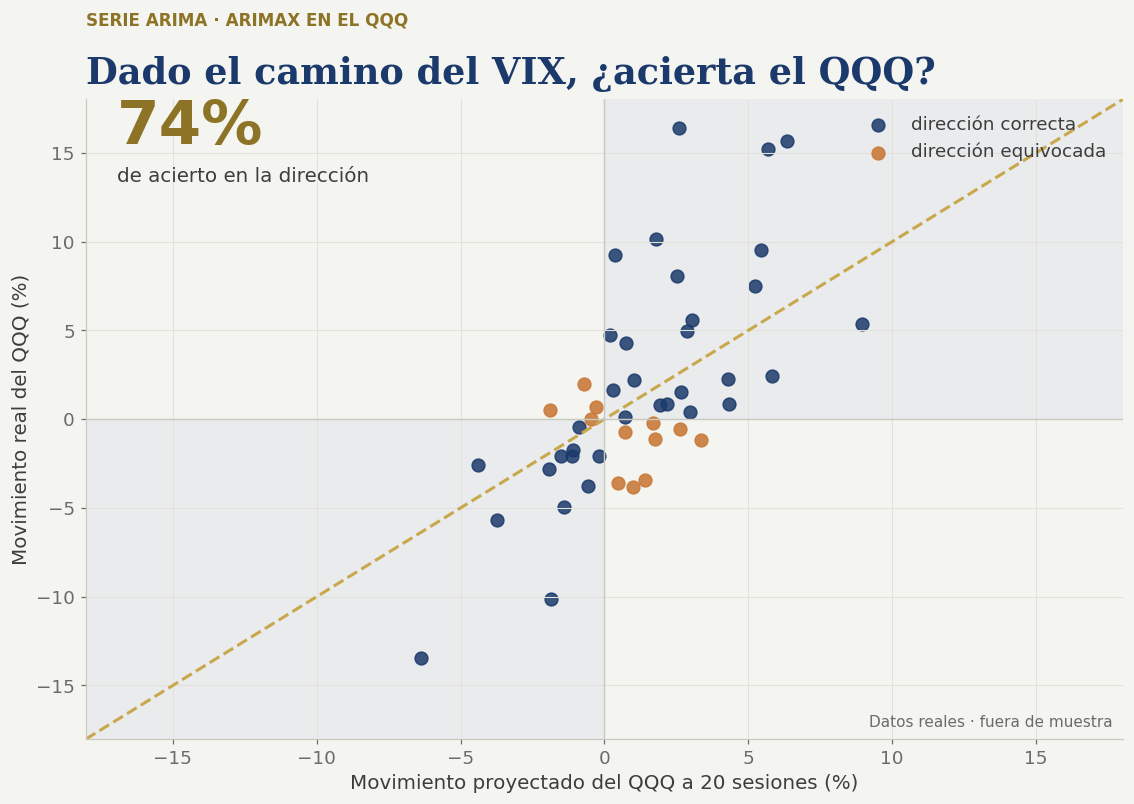

Proyecciones evaluadas: 47 (ventanas de 20 sesiones, fuera de muestra)
ARIMAX con el camino real del VIX: acierta la dirección 74% · correlación 0.68
ARIMA solo (sin VIX):              acierta la dirección 57% · correlación 0.14


In [ ]:
VENTANA, PASO = 20, 5
filt_x, filt_a = arimax.apply(y, exog=lv), arima.apply(y)
proy_x, proy_a, obs, inicio = [], [], [], []
for s in range(ini, len(y) - VENTANA + 1, PASO):
    fx = filt_x.get_prediction(start=s, end=s + VENTANA - 1, dynamic=True).predicted_mean
    fa = filt_a.get_prediction(start=s, end=s + VENTANA - 1, dynamic=True).predicted_mean
    proy_x.append((np.exp(fx.iloc[-1] - y.iloc[s - 1]) - 1) * 100)
    proy_a.append((np.exp(fa.iloc[-1] - y.iloc[s - 1]) - 1) * 100)
    obs.append((np.exp(y.iloc[s + VENTANA - 1] - y.iloc[s - 1]) - 1) * 100)
    inicio.append(fechas[s])
proy_x, proy_a, obs = map(np.array, (proy_x, proy_a, obs))
hit_x = (np.sign(proy_x) == np.sign(obs)).mean() * 100
hit_a = (np.sign(proy_a) == np.sign(obs)).mean() * 100
corr_x = np.corrcoef(proy_x, obs)[0, 1]

fig, ax = plt.subplots(figsize=(10.5, 7.5))
lim = np.max(np.abs(np.r_[proy_x, obs])) * 1.1
ax.axhspan(0, lim, xmin=0.5, color=SOFT, alpha=0.35, lw=0)
ax.axhspan(-lim, 0, xmax=0.5, color=SOFT, alpha=0.35, lw=0)
ax.plot([-lim, lim], [-lim, lim], color=GOLD, lw=2, ls='--')
ok = np.sign(proy_x) == np.sign(obs)
ax.scatter(proy_x[ok], obs[ok], s=70, color=MAIN, alpha=0.85, label='dirección correcta')
ax.scatter(proy_x[~ok], obs[~ok], s=70, color=ALERT, alpha=0.9, label='dirección equivocada')
ax.axhline(0, color=P['SPINE'], lw=0.9); ax.axvline(0, color=P['SPINE'], lw=0.9)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel(f'Movimiento proyectado del QQQ a {VENTANA} sesiones (%)')
ax.set_ylabel('Movimiento real del QQQ (%)')
ax.text(0.03, 0.93, f'{hit_x:.0f}%', transform=ax.transAxes, fontsize=40, fontfamily=NUM,
        fontweight='semibold', color=GOLD_TXT)
ax.text(0.03, 0.87, 'de acierto en la dirección', transform=ax.transAxes, fontsize=13, color=FG)
marca(ax, 'Dado el camino del VIX, ¿acierta el QQQ?')
ax.legend(loc='upper right', fontsize=12)
rotulo(ax, 'Datos reales · fuera de muestra')
plt.tight_layout(); plt.show()

print(f'Proyecciones evaluadas: {len(obs)} (ventanas de {VENTANA} sesiones, fuera de muestra)')
print(f'ARIMAX con el camino real del VIX: acierta la dirección {hit_x:.0f}% · correlación {corr_x:.2f}')
print(f'ARIMA solo (sin VIX):              acierta la dirección {hit_a:.0f}% · correlación {np.corrcoef(proy_a, obs)[0,1]:.2f}')

### Figura 5 · Proyección del QQQ en tres escenarios del VIX
Se reentrena el ARIMAX con **toda** la muestra (mismo orden) y se proyectan `H` sesiones bajo tres caminos del VIX. Edita `ESCENARIOS` para probar los tuyos: cada uno es el múltiplo del VIX actual al que se llega en `DIAS_TRANSICION` sesiones y luego se mantiene.
La franja es el intervalo de 80% del escenario base. Lee del `print()` el precio y el cambio de cada escenario: esas son las cifras del video.

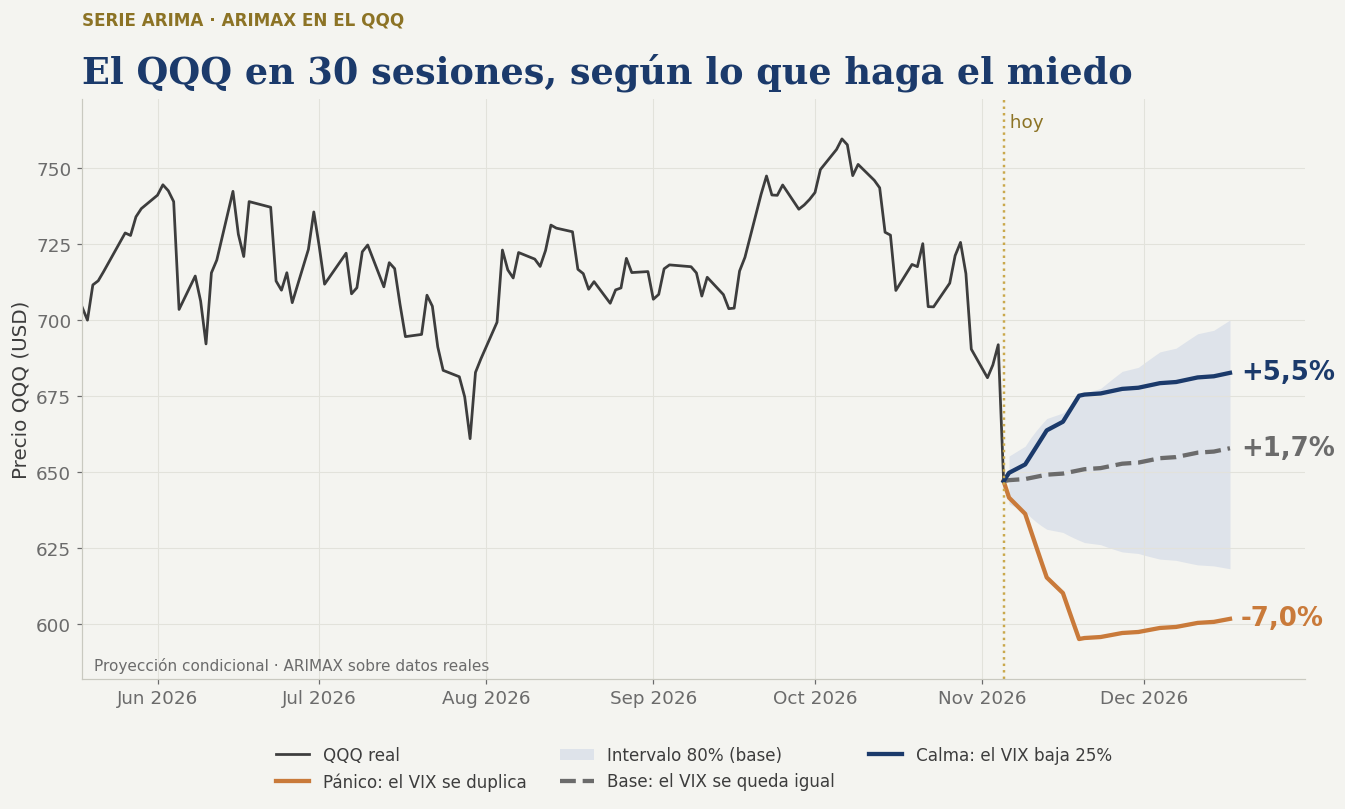

Último cierre (05-11-2026): QQQ $647.05 · VIX 28.18
Pánico: el VIX se duplica      VIX →  56.4   QQQ → $601.76  (-7.0%)
Base: el VIX se queda igual    VIX →  28.2   QQQ → $657.89  (+1.7%)
Calma: el VIX baja 25%         VIX →  21.1   QQQ → $682.70  (+5.5%)


In [ ]:
H, DIAS_TRANSICION, HIST = 30, 10, 120
ESCENARIOS = {                     # nombre: (múltiplo del VIX actual, color)
    'Pánico: el VIX se duplica': (2.00, ALERT),
    'Base: el VIX se queda igual': (1.00, MUTED),
    'Calma: el VIX baja 25%': (0.75, MAIN),
}

final = ajustar(y, lv, ORDEN)
lv0, p0, v0 = lv.iloc[-1], df['qqq'].iloc[-1], df['vix'].iloc[-1]
fut = pd.bdate_range(fechas[-1] + pd.Timedelta(days=1), periods=H)

fig, ax = plt.subplots(figsize=(12.5, 7.6))
ax.plot(fechas[-HIST:], df['qqq'].values[-HIST:], color=FG, lw=1.8, label='QQQ real')
salida = []
for nombre, (mult, col) in ESCENARIOS.items():
    camino = np.r_[np.linspace(lv0, lv0 + np.log(mult), DIAS_TRANSICION + 1)[1:],
                   np.full(H - DIAS_TRANSICION, lv0 + np.log(mult))]
    fc = final.get_forecast(steps=H, exog=pd.DataFrame({'log_vix': camino}))
    centro = np.exp(fc.predicted_mean.values)
    if mult == 1.0:
        ic = np.exp(fc.conf_int(alpha=0.20).values)
        ax.fill_between(fut, ic[:, 0], ic[:, 1], color=SOFT, alpha=0.7, lw=0, label='Intervalo 80% (base)')
    ax.plot(np.r_[fechas[-1:], fut], np.r_[p0, centro], color=col, lw=2.8, label=nombre,
            ls='--' if mult == 1.0 else '-')
    ax.text(fut[-1] + pd.Timedelta(days=2), centro[-1], f'{pct((centro[-1]/p0 - 1)*100)}',
            fontsize=17, fontfamily=NUM, fontweight='semibold', color=col, va='center')
    salida.append((nombre, v0 * mult, centro[-1], (centro[-1] / p0 - 1) * 100))
ax.axvline(fechas[-1], color=GOLD, lw=1.6, ls=':')
ax.text(fechas[-1], ax.get_ylim()[1], ' hoy', color=GOLD_TXT, fontsize=12, va='top')
ax.set_xlim(fechas[-HIST], fut[-1] + pd.Timedelta(days=14))
ax.set_ylabel(f'Precio {TICKER} (USD)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
marca(ax, f'El QQQ en {H} sesiones, según lo que haga el miedo')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=3, fontsize=11)
ax.margins(y=0.08)
ax.text(0.01, 0.015, 'Proyección condicional · ARIMAX sobre datos reales', transform=ax.transAxes, fontsize=10, color=MUTED)
plt.tight_layout(); plt.show()

print(f'Último cierre ({fechas[-1]:%d-%m-%Y}): QQQ ${p0:,.2f} · VIX {v0:.2f}')
for nombre, v_fin, precio_fin, cambio in salida:
    print(f'{nombre:<30} VIX → {v_fin:5.1f}   QQQ → ${precio_fin:,.2f}  ({cambio:+.1f}%)')